# Applied Finance with Python
## Case Study 4: The Roller Coaster (reference solution)

After her first quarterly report, Ms. Keller has two questions:
*"Infineon and SAP went down steeply along the way. I could not have slept at night.
And my neighbour says he simply bought the DAX and did just as well. Is that true?"*

| Task | Question | Finance concept |
|---|---|---|
| 1 · Stock vs. DAX | Did each stock beat the DAX over the **same period**? | Benchmarking, rebasing |
| 2 · Measuring risk | How bumpy was the ride? | Annualised volatility (+ max. drawdown) |
| 3 · Return vs. risk | Where does each stock sit on the risk/return map? | Risk/return trade-off |
| 4 · Was it worth it? | Which stock should she have replaced by the DAX? | Return per unit of risk |

> **Lecturer note:** this is the reference solution. It extends the notebook from Case Study 3
> (same portfolio cell, same data-load pattern, same colours). The only new input is the benchmark.

## 1 · Setup

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf
from matplotlib.ticker import PercentFormatter

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
})

### Client portfolio and benchmark
Change only this cell to run the analysis for another client.

In [2]:
portfolio = [
    {"name": "Allianz SE",               "ticker": "ALV.DE",  "buy_date": "2021-09-30"},
    {"name": "SAP SE",                   "ticker": "SAP.DE",  "buy_date": "2022-03-15"},
    {"name": "Infineon Technologies AG", "ticker": "IFX.DE",  "buy_date": "2022-06-01"},
    {"name": "Deutsche Telekom AG",      "ticker": "DTE.DE",  "buy_date": "2023-01-03"},
    {"name": "Münchener Rück AG",        "ticker": "MUV2.DE", "buy_date": "2023-09-29"},
]

benchmark = {"name": "DAX", "ticker": "^GDAXI"}

end_date = "2026-09-23"   # date of the evaluation (inclusive)

SNAPSHOT_FILE = Path("data/keller_prices_snapshot_case4.csv")   # Case 3 snapshot has no DAX
USE_SNAPSHOT = False       # True: read the frozen CSV instead of downloading from Yahoo
OUTPUT_DIR = Path("reference_plots_case4")
TRADING_DAYS = 252         # used to annualise daily volatility

## 2 · Data load
Same pattern as in Case Study 3, but the benchmark is downloaded together with the stocks.

**Compare like with like.** The DAX (`^GDAXI`) is a *performance index*: dividends are reinvested
in the index level. For the stocks we therefore use `Adj Close` (dividends included).
Comparing the DAX with plain `Close` prices would make every stock look worse than it was,
and Allianz the most.

*Source: Yahoo Finance via `yfinance`, Xetra listings (`.DE`), prices in EUR; DAX performance index (`^GDAXI`).*

In [4]:
def download_prices(tickers, start, end_date):
    # Download Close and Adj Close. Returns a DataFrame with MultiIndex columns (field, ticker).
    end_exclusive = (pd.Timestamp(end_date) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")  # yfinance: end is exclusive
    data = yf.download(tickers, start=start, end=end_exclusive, auto_adjust=False, progress=False)
    return data[["Close", "Adj Close"]]


def load_prices(portfolio, benchmark, end_date):
    if USE_SNAPSHOT:
        return pd.read_csv(SNAPSHOT_FILE, header=[0, 1], index_col=0, parse_dates=True)
    tickers = [s["ticker"] for s in portfolio] + [benchmark["ticker"]]
    start = min(s["buy_date"] for s in portfolio)
    data = download_prices(tickers, start, end_date)
    SNAPSHOT_FILE.parent.mkdir(parents=True, exist_ok=True)
    data.to_csv(SNAPSHOT_FILE)
    return data


prices = load_prices(portfolio, benchmark, end_date)
adj_close = prices["Adj Close"]

print(f"{len(prices)} trading days from {prices.index[0].date()} to {prices.index[-1].date()}")
adj_close.tail()

1270 trading days from 2021-09-30 to 2026-09-23


Ticker,ALV.DE,DTE.DE,IFX.DE,MUV2.DE,SAP.DE,^GDAXI
Date,,,,,,
2026-09-17,451.100006,28.299999,54.400002,510.600006,188.000000,25716.710938
2026-09-18,443.299988,27.110001,55.860001,505.799988,183.119995,25304.060547
2026-09-21,445.100006,27.290001,58.290001,508.799988,182.860001,25575.009766
2026-09-22,430.200012,27.110001,60.130001,501.799988,182.320007,25578.849609
2026-09-23,413.100006,26.830000,58.570000,502.600006,186.460007,25410.630859


### Helpers
`since_purchase` and the colours are unchanged from Case Study 3. New is `stock_and_benchmark`:
it puts a stock and the DAX side by side **from the same first trading day**, so both are measured
over exactly the same period. `rebase`, `cagr`, `volatility` and `max_drawdown` work on any price series,
so they are reused for stocks and the DAX alike.

In [5]:
PALETTE = ["#1f4e79", "#e8a202", "#2e8b57", "#c0392b", "#7d3c98", "#5d6d7e", "#16a085", "#d35400"]
COLORS = {s["ticker"]: PALETTE[i % len(PALETTE)] for i, s in enumerate(portfolio)}
DAX_COLOR = "#7f7f7f"
OUTPUT_DIR.mkdir(exist_ok=True)


def since_purchase(series, buy_date):
    # Price series from the first trading day on or after the purchase date.
    return series.loc[buy_date:].dropna()


def stock_and_benchmark(adj_close, stock, benchmark):
    # Stock and benchmark on common trading days from the purchase date onwards.
    pair = adj_close[[stock["ticker"], benchmark["ticker"]]].loc[stock["buy_date"]:].dropna()
    pair.columns = ["stock", "benchmark"]
    return pair


def rebase(prices, base=100.0):
    # 100 € invested on the first day would be worth this much on each later day.
    return base * prices / prices.iloc[0]


def total_return(prices):
    return prices.iloc[-1] / prices.iloc[0] - 1


def cagr(prices):
    # Compound annual growth rate, as in Case Studies 1 and 2.
    years = (prices.index[-1] - prices.index[0]).days / 365.25
    return (prices.iloc[-1] / prices.iloc[0]) ** (1 / years) - 1


def volatility(prices, trading_days=TRADING_DAYS):
    # Annualised volatility: standard deviation of daily returns, scaled to one year.
    daily_returns = prices.pct_change().dropna()
    return daily_returns.std() * np.sqrt(trading_days)


def max_drawdown(prices):
    # Largest fall from a previous peak (Case Study 3).
    return (prices / prices.cummax() - 1).min()

## 3 · Task 1: Each stock vs. the DAX over the same period

One small chart per stock. In each chart, the stock **and** the DAX start at 100 on the purchase date.
The shaded area shows the gap: **green** where the stock is ahead of the DAX, **red** where it is behind.
The end values tell Ms. Keller what 100 € would have become in the stock and in the DAX.

Why one chart per stock? Every stock was bought on a different date, so each stock needs
its own "DAX twin" that starts on the same day. A single DAX line would not be a fair comparison.

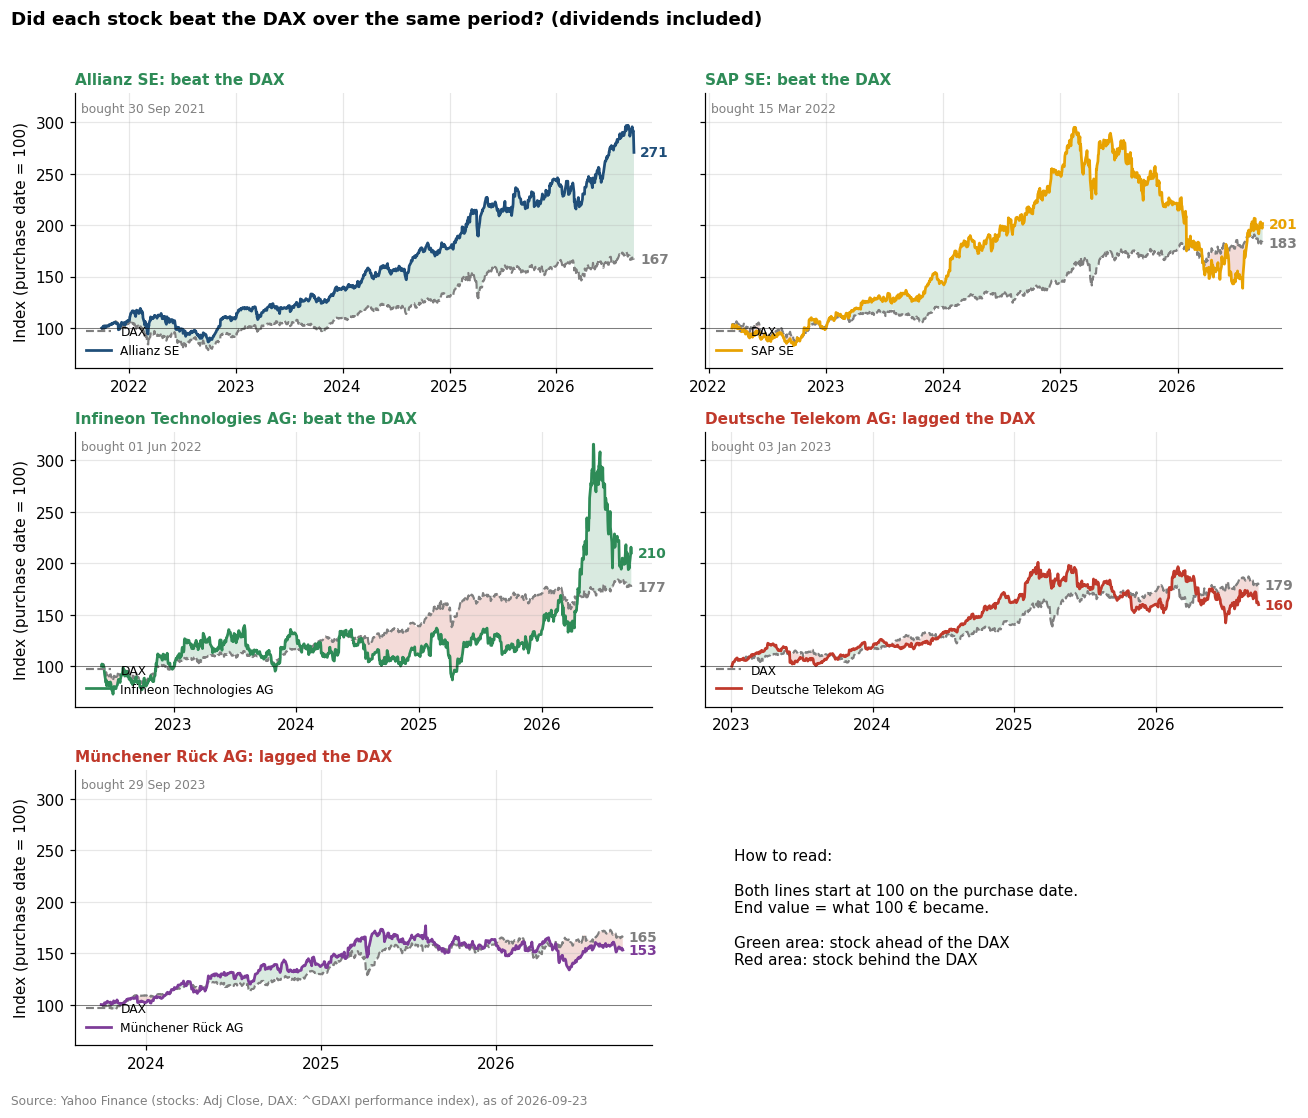

In [6]:
def plot_vs_benchmark(adj_close, portfolio, benchmark, end_date, ncols=2):
    n = len(portfolio)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.4 * nrows), sharey=True, squeeze=False)
    axes = axes.ravel()

    for ax, stock in zip(axes, portfolio):
        pair = rebase(stock_and_benchmark(adj_close, stock, benchmark))
        s, b = pair["stock"], pair["benchmark"]
        color = COLORS[stock["ticker"]]

        ax.fill_between(pair.index, s, b, where=s >= b, color="#2e8b57", alpha=0.18, linewidth=0, interpolate=True)
        ax.fill_between(pair.index, s, b, where=s < b, color="#c0392b", alpha=0.18, linewidth=0, interpolate=True)
        ax.plot(pair.index, b, color=DAX_COLOR, linewidth=1.4, linestyle="--", label=benchmark["name"])
        ax.plot(pair.index, s, color=color, linewidth=1.8, label=stock["name"])
        ax.axhline(100, color="black", linewidth=0.6, alpha=0.5)

        for value, c in [(s.iloc[-1], color), (b.iloc[-1], DAX_COLOR)]:
            ax.annotate(f"{value:.0f}", xy=(pair.index[-1], value), xytext=(4, 0),
                        textcoords="offset points", va="center", color=c, fontweight="bold", fontsize=9)

        beat = s.iloc[-1] >= b.iloc[-1]
        verdict = "beat the DAX" if beat else "lagged the DAX"
        ax.set_title(f"{stock['name']}: {verdict}", loc="left", fontsize=10, fontweight="bold",
                     color="#2e8b57" if beat else "#c0392b")
        ax.text(0.01, 0.97, f"bought {pair.index[0]:%d %b %Y}", transform=ax.transAxes,
                fontsize=8, color="grey", va="top")
        ax.legend(loc="lower left", frameon=False, fontsize=8)
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        ax.set_xlim(right=adj_close.index[-1] + pd.Timedelta(days=60))   # room for end labels

    for ax in axes[n:]:          # empty panel(s): use one for a short reading guide
        ax.axis("off")
    if n < len(axes):
        axes[n].text(0.05, 0.5,
                     "How to read:\n\n"
                     "Both lines start at 100 on the purchase date.\n"
                     "End value = what 100 € became.\n\n"
                     "Green area: stock ahead of the DAX\n"
                     "Red area: stock behind the DAX",
                     fontsize=10, va="center", transform=axes[n].transAxes)

    for ax in axes[::ncols][:nrows]:
        ax.set_ylabel("Index (purchase date = 100)")
    fig.suptitle("Did each stock beat the DAX over the same period? (dividends included)",
                 x=0.01, ha="left", fontweight="bold", fontsize=12)
    fig.text(0.01, 0.005, f"Source: Yahoo Finance (stocks: Adj Close, DAX: ^GDAXI performance index), as of {end_date}",
             fontsize=8, color="grey")
    fig.tight_layout(rect=(0, 0.02, 1, 0.97))
    return fig


fig1 = plot_vs_benchmark(adj_close, portfolio, benchmark, end_date)
fig1.savefig(OUTPUT_DIR / "chart1_stock_vs_dax.png", dpi=150)
plt.show()

The same result as a table: total return and CAGR of each stock and of its DAX twin.

In [7]:
def performance_table(adj_close, portfolio, benchmark):
    rows = []
    for stock in portfolio:
        pair = stock_and_benchmark(adj_close, stock, benchmark)
        rows.append({
            "Stock": stock["name"],
            "Purchase": pair.index[0].date(),
            "Years": (pair.index[-1] - pair.index[0]).days / 365.25,
            "Total return": total_return(pair["stock"]),
            "Total return DAX": total_return(pair["benchmark"]),
            "CAGR": cagr(pair["stock"]),
            "CAGR DAX": cagr(pair["benchmark"]),
        })
    df = pd.DataFrame(rows).set_index("Stock")
    df["CAGR vs. DAX"] = df["CAGR"] - df["CAGR DAX"]   # in percentage points per year
    return df


perf = performance_table(adj_close, portfolio, benchmark)
perf.style.format({"Years": "{:.1f}", **{c: "{:+.1%}" for c in perf.columns if c not in ("Purchase", "Years")}})

,Purchase,Years,Total return,Total return DAX,CAGR,CAGR DAX,CAGR vs. DAX
Stock,,,,,,,
Allianz SE,2021-09-30,5.0,+170.6%,+66.5%,+22.1%,+10.8%,+11.3%
SAP SE,2022-03-15,4.5,+101.4%,+82.6%,+16.7%,+14.2%,+2.5%
Infineon Technologies AG,2022-06-01,4.3,+110.2%,+77.2%,+18.8%,+14.2%,+4.6%
Deutsche Telekom AG,2023-01-03,3.7,+59.9%,+79.2%,+13.4%,+17.0%,-3.5%
Münchener Rück AG,2023-09-29,3.0,+53.0%,+65.1%,+15.3%,+18.3%,-3.0%


## 4 · Task 2: How can we measure risk?

### Main measure: annualised volatility
**In plain words:** volatility measures *how much the value jumps up and down*.
A stock with low volatility moves calmly; a stock with high volatility swings a lot, in both directions.

**How it is calculated:**
1. Daily return: `r_t = P_t / P_(t-1) − 1` (with `Adj Close`, so dividend days are not counted as losses)
2. Standard deviation of all daily returns = typical daily swing
3. Scale to one year: `σ_annual = σ_daily × √252` (about 252 trading days per year)

**What to tell Ms. Keller:** *"A volatility of 30 % means that in a normal year the value
can easily end up about 30 % higher or lower than expected. With 15 % the ride is twice as calm."*

### Companion measure: maximum drawdown (from Case Study 3)
Volatility is a statistical number. For a client, the **maximum drawdown** is often easier to feel:
the largest loss from a previous peak, i.e. *"the worst moment you would have had to sit through"*.
It is exactly what Ms. Keller describes with *"I could not have slept at night"*.

> **Lecturer note:** the task asks for one measure. Volatility is used for the scatter plot because it is the
> standard x-axis of a risk/return diagram. Max. drawdown is shown as a plain-language companion.
> Both are calculated for each stock **and** its DAX twin over the same period.

In [ ]:
def risk_table(adj_close, portfolio, benchmark):
    rows = []
    for stock in portfolio:
        pair = stock_and_benchmark(adj_close, stock, benchmark)
        rows.append({
            "Stock": stock["name"],
            "Volatility": volatility(pair["stock"]),
            "Volatility DAX": volatility(pair["benchmark"]),
            "Max. drawdown": max_drawdown(pair["stock"]),
            "Max. drawdown DAX": max_drawdown(pair["benchmark"]),
        })
    return pd.DataFrame(rows).set_index("Stock")


risk = risk_table(adj_close, portfolio, benchmark)

# The DAX over the full period (from the first purchase), as a single reference value
dax_full = adj_close[benchmark["ticker"]].loc[min(s["buy_date"] for s in portfolio):].dropna()
print(f"DAX over the full period: volatility {volatility(dax_full):.1%}, max. drawdown {max_drawdown(dax_full):.1%}")

risk.style.format("{:.1%}")

DAX over the full period: volatility 17.0%, max. drawdown -26.4%


,Volatility,Volatility DAX,Max. drawdown,Max. drawdown DAX
Stock,,,,
Allianz SE,19.3%,17.0%,-27.5%,-26.4%
SAP SE,29.1%,16.1%,-53.0%,-19.2%
Infineon Technologies AG,41.8%,15.8%,-38.6%,-18.3%
Deutsche Telekom AG,20.6%,15.0%,-29.3%,-16.0%
Münchener Rück AG,21.3%,15.3%,-24.3%,-16.0%


A visual version for the client: how bumpy was each stock compared with the DAX over the same period?

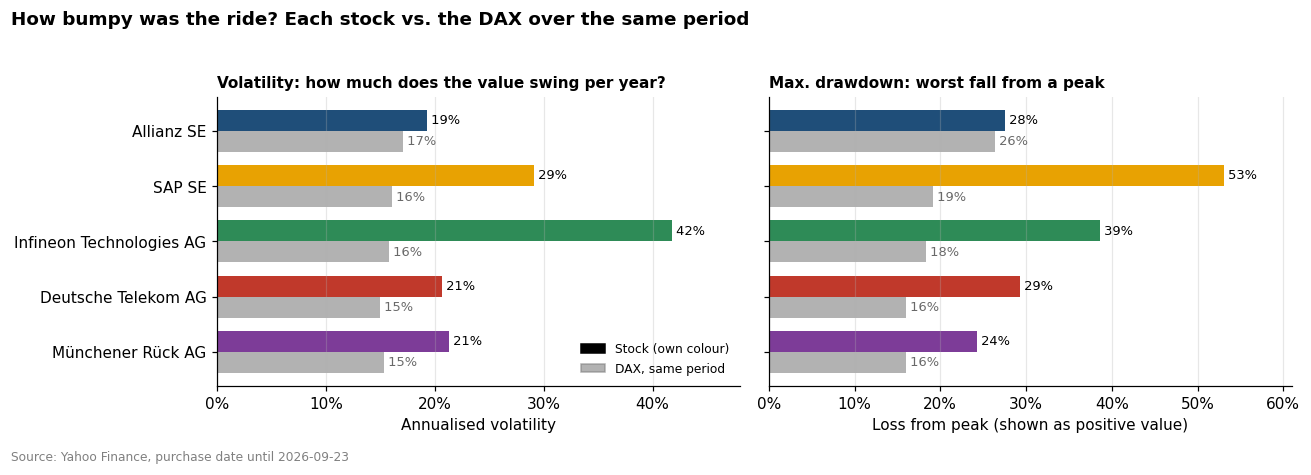

In [ ]:
def plot_risk_bars(risk, portfolio, end_date):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
    y = np.arange(len(risk))
    h = 0.38
    colors = [COLORS[s["ticker"]] for s in portfolio]

    for ax, col, title in [(axes[0], "Volatility", "Volatility: how much does the value swing per year?"),
                           (axes[1], "Max. drawdown", "Max. drawdown: worst fall from a peak")]:
        stock_vals = risk[col].abs()
        dax_vals = risk[f"{col} DAX"].abs()
        ax.barh(y - h / 2, stock_vals, height=h, color=colors, label="Stock")
        ax.barh(y + h / 2, dax_vals, height=h, color=DAX_COLOR, alpha=0.6, label="DAX (same period)")
        for yi, v in zip(y, stock_vals):
            ax.text(v, yi - h / 2, f" {v:.0%}", va="center", fontsize=8.5)
        for yi, v in zip(y, dax_vals):
            ax.text(v, yi + h / 2, f" {v:.0%}", va="center", fontsize=8.5, color="dimgrey")
        ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
        ax.set_title(title, loc="left", fontsize=10, fontweight="bold")
        ax.grid(axis="y", visible=False)
        ax.margins(x=0.15)

    axes[0].set_yticks(y, risk.index)
    axes[0].invert_yaxis()
    axes[1].set_xlabel("Loss from peak (shown as positive value)")
    axes[0].set_xlabel("Annualised volatility")
    from matplotlib.patches import Patch
    axes[0].legend(handles=[Patch(color="black", label="Stock (own colour)"),
                            Patch(color=DAX_COLOR, alpha=0.6, label="DAX, same period")],
                   loc="lower right", frameon=False, fontsize=8)
    fig.suptitle("How bumpy was the ride? Each stock vs. the DAX over the same period",
                 x=0.01, ha="left", fontweight="bold", fontsize=12)
    fig.text(0.01, 0.005, f"Source: Yahoo Finance, purchase date until {end_date}", fontsize=8, color="grey")
    fig.tight_layout(rect=(0, 0.03, 1, 0.95))
    return fig


fig2 = plot_risk_bars(risk, portfolio, end_date)
fig2.savefig(OUTPUT_DIR / "chart2_risk.png", dpi=150)
plt.show()

## 5 · Task 3: Return vs. risk

Each stock is a filled dot. Its DAX twin (same period) is a hollow dot in the same colour,
connected by a dotted line. (The DAX twin of the earliest purchase is also the DAX over the full period.)

**How to read it:** up is good (more return), right is uncomfortable (more risk).
A stock that sits **above and to the left** of its DAX twin was better in both respects.
A stock **below and to the right** brought more stress for less return.

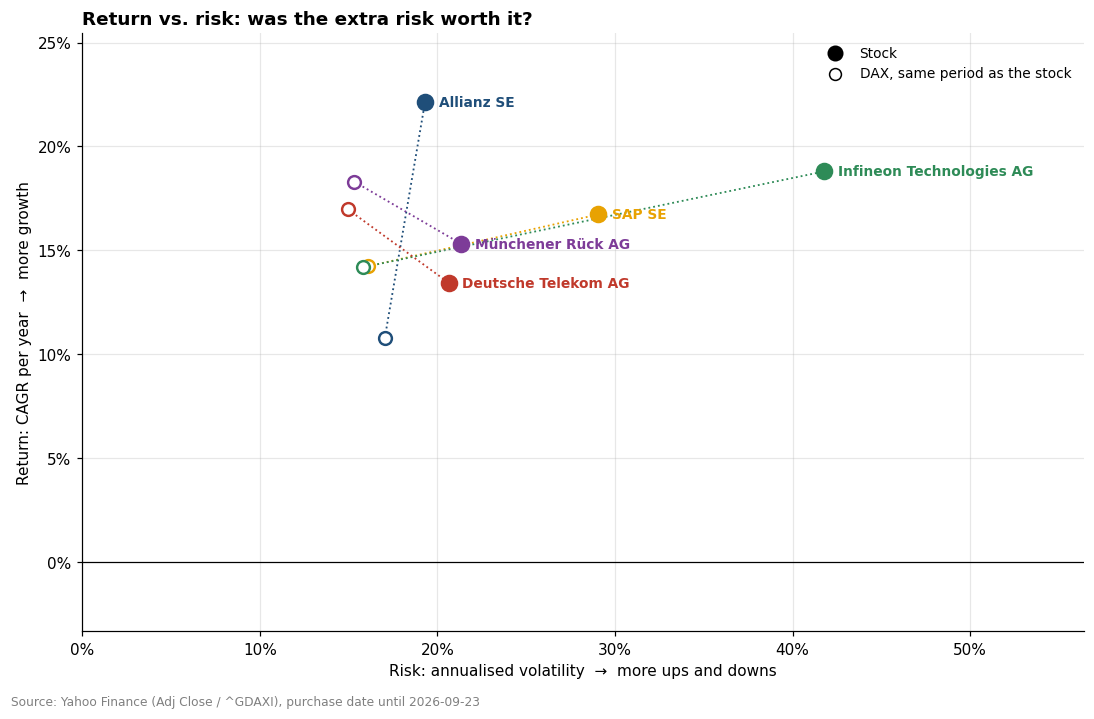

In [10]:
def label_points(ax, points, min_gap=14):
    # Label points to their right; push labels apart vertically if they would overlap (gap in pixels).
    fig = ax.figure
    fig.canvas.draw()
    to_px = ax.transData.transform
    placed = []   # (x_px, y_px) of labels already placed
    for x, y, text, color in sorted(points, key=lambda p: -p[1]):
        px, py = to_px((x, y))
        label_y = py
        for qx, qy in placed:
            if abs(px - qx) < 160 and abs(label_y - qy) < min_gap:
                label_y = qy - min_gap
        placed.append((px, label_y))
        dy_points = (label_y - py) * 72 / fig.dpi   # pixels -> points, independent of savefig dpi
        ax.annotate(text, xy=(x, y), xytext=(9, dy_points), textcoords="offset points",
                    va="center", fontsize=9, fontweight="bold", color=color)


def plot_risk_return(perf, risk, portfolio, end_date):
    fig, ax = plt.subplots(figsize=(10, 6.5))

    for stock in portfolio:
        name, color = stock["name"], COLORS[stock["ticker"]]
        x_s, y_s = risk.loc[name, "Volatility"], perf.loc[name, "CAGR"]
        x_b, y_b = risk.loc[name, "Volatility DAX"], perf.loc[name, "CAGR DAX"]
        ax.plot([x_b, x_s], [y_b, y_s], color=color, linestyle=":", linewidth=1.2, zorder=1)
        ax.scatter(x_b, y_b, s=70, facecolors="white", edgecolors=color, linewidths=1.6, zorder=2)
        ax.scatter(x_s, y_s, s=110, color=color, zorder=3)

    # legend entries for the marker types
    ax.scatter([], [], s=90, color="black", label="Stock")
    ax.scatter([], [], s=60, facecolors="white", edgecolors="black", label="DAX, same period as the stock")

    ax.axhline(0, color="black", linewidth=0.8)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_xlabel("Risk: annualised volatility  →  more ups and downs")
    ax.set_ylabel("Return: CAGR per year  →  more growth")
    ax.set_xlim(0, max(risk["Volatility"].max(), risk["Volatility DAX"].max()) * 1.35)  # room for labels
    ax.margins(y=0.15)
    label_points(ax, [(risk.loc[s["name"], "Volatility"], perf.loc[s["name"], "CAGR"], s["name"],
                       COLORS[s["ticker"]]) for s in portfolio])
    ax.legend(loc="upper right", frameon=False, fontsize=9)
    ax.set_title("Return vs. risk: was the extra risk worth it?", loc="left", fontweight="bold")
    fig.text(0.01, 0.005, f"Source: Yahoo Finance (Adj Close / ^GDAXI), purchase date until {end_date}",
             fontsize=8, color="grey")
    fig.tight_layout(rect=(0, 0.02, 1, 1))
    return fig


fig3 = plot_risk_return(perf, risk, portfolio, end_date)
fig3.savefig(OUTPUT_DIR / "chart3_risk_return.png", dpi=150)
plt.show()

## 6 · Task 4: Was the risk worth it?

Two questions per stock, each compared with its DAX twin:

1. **Return:** did the stock grow faster than the DAX (higher CAGR)?
2. **Return per unit of risk:** `CAGR / volatility`. How much return did Ms. Keller get for each
   "unit" of nervousness? If this ratio is higher than the DAX's, the extra risk was rewarded.

| Verdict | Rule |
|---|---|
| ✅ Risk paid off | higher CAGR **and** higher return per unit of risk than the DAX |
| ⚠️ More return, but bumpier | higher CAGR, but lower return per unit of risk |
| ❌ DAX would have been better | lower CAGR than the DAX → candidate for replacement |

> **Lecturer note:** `CAGR / volatility` is a simplified Sharpe ratio without the risk-free rate.
> Groups that find the Sharpe ratio can subtract a risk-free rate (e.g. €STR or 1-year Bund yield);
> with interest rates around 2–3 % the ranking can change for low-return stocks, which is a good discussion point.

In [11]:
def verdict(row):
    if row["CAGR"] < row["CAGR DAX"]:
        return "DAX would have been better"
    if row["Return/risk"] >= row["Return/risk DAX"]:
        return "Risk paid off"
    return "More return, but bumpier"


summary = perf[["CAGR", "CAGR DAX"]].join(risk[["Volatility", "Volatility DAX", "Max. drawdown"]])
summary["Return/risk"] = summary["CAGR"] / summary["Volatility"]
summary["Return/risk DAX"] = summary["CAGR DAX"] / summary["Volatility DAX"]
summary["Verdict"] = summary.apply(verdict, axis=1)
summary = summary.sort_values("Return/risk", ascending=False)

pct_cols = ["CAGR", "CAGR DAX", "Volatility", "Volatility DAX", "Max. drawdown"]
summary.style.format({**{c: "{:+.1%}" for c in pct_cols}, "Return/risk": "{:.2f}", "Return/risk DAX": "{:.2f}"})

,CAGR,CAGR DAX,Volatility,Volatility DAX,Max. drawdown,Return/risk,Return/risk DAX,Verdict
Stock,,,,,,,,
Allianz SE,+22.1%,+10.8%,+19.3%,+17.0%,-27.5%,1.15,0.63,Risk paid off
Münchener Rück AG,+15.3%,+18.3%,+21.3%,+15.3%,-24.3%,0.72,1.20,DAX would have been better
Deutsche Telekom AG,+13.4%,+17.0%,+20.6%,+15.0%,-29.3%,0.65,1.13,DAX would have been better
SAP SE,+16.7%,+14.2%,+29.1%,+16.1%,-53.0%,0.58,0.88,"More return, but bumpier"
Infineon Technologies AG,+18.8%,+14.2%,+41.8%,+15.8%,-38.6%,0.45,0.90,"More return, but bumpier"


### Plain-language answers for Ms. Keller
Generated from the table above, so they update automatically for every client.
They are the starting point for the presentation, not the final wording.

In [12]:
def client_sentences(summary, perf):
    lines = []
    for name, row in summary.iterrows():
        years = perf.loc[name, "Years"]
        diff = row["CAGR"] - row["CAGR DAX"]
        better_worse = "more" if diff >= 0 else "less"
        calmer = "calmer" if row["Volatility"] < row["Volatility DAX"] else "bumpier"
        lines.append(
            f"- {name}: over {years:.1f} years it grew by {row['CAGR']:.1%} per year, "
            f"{abs(diff) * 100:.1f} percentage points {better_worse} than the DAX. The ride was {calmer} than the DAX "
            f"(worst fall: {row['Max. drawdown']:.0%}). Verdict: {row['Verdict']}."
        )
    replace = summary.index[summary["Verdict"] == "DAX would have been better"].tolist()
    lines.append("")
    if replace:
        lines.append("In hindsight, the DAX would have been the better choice instead of: " + ", ".join(replace) + ".")
    else:
        lines.append("In hindsight, every stock did at least as well as the DAX over its own holding period.")
    return "\n".join(lines)


print(client_sentences(summary, perf))

- Allianz SE: over 5.0 years it grew by 22.1% per year, 11.3 percentage points more than the DAX. The ride was bumpier than the DAX (worst fall: -28%). Verdict: Risk paid off.
- Münchener Rück AG: over 3.0 years it grew by 15.3% per year, 3.0 percentage points less than the DAX. The ride was bumpier than the DAX (worst fall: -24%). Verdict: DAX would have been better.
- Deutsche Telekom AG: over 3.7 years it grew by 13.4% per year, 3.5 percentage points less than the DAX. The ride was bumpier than the DAX (worst fall: -29%). Verdict: DAX would have been better.
- SAP SE: over 4.5 years it grew by 16.7% per year, 2.5 percentage points more than the DAX. The ride was bumpier than the DAX (worst fall: -53%). Verdict: More return, but bumpier.
- Infineon Technologies AG: over 4.3 years it grew by 18.8% per year, 4.6 percentage points more than the DAX. The ride was bumpier than the DAX (worst fall: -39%). Verdict: More return, but bumpier.

In hindsight, the DAX would have been the better 

## 7 · Answers for Ms. Keller

*To be completed after running the notebook with the final snapshot.*

1. **Stock vs. DAX:** …
2. **Risk measure:** volatility = how strongly the value swings per year; max. drawdown = worst fall you would have sat through. Highest risk: …
3. **Return vs. risk:** …
4. **Was the risk worth it? Which stock should have been the DAX?** …

**Is the neighbour right?** Only partly: the answer depends on the stock *and* on the period.
Each stock has to be compared with the DAX from its own purchase date, and the DAX already contains
reinvested dividends, so the stocks must be measured including dividends as well.